## CA1 - Joao Luis Ribeiro Goes - Local Tourism in Republic of Irleand after,during and before Pandemic(Covid-19).

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from sklearn.preprocessing import LabelEncoder
from sklearn import linear_model
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
wr.filterwarnings('ignore')
import datetime


In [2]:
# Importing the dataset
# looking at the dataset
#ASM03 Air and Sea Travel
df = pd.read_csv("ASM03.20261003T131035.csv")
df.head()

,STATISTIC Label,Month,Country,Direction,UNIT,VALUE
0,Air and Sea Travel,2010 January,Great Britain,Arrivals,Thousand,361.5
1,Air and Sea Travel,2010 January,Great Britain,Departures,Thousand,407.6
2,Air and Sea Travel,2010 January,Other UK (1),Arrivals,Thousand,0.9
3,Air and Sea Travel,2010 January,Other UK (1),Departures,Thousand,1.1
4,Air and Sea Travel,2010 January,Belgium,Arrivals,Thousand,12.5


In [3]:
#Return ten random sample row of the DataFrame
df.sample(10)

,STATISTIC Label,Month,Country,Direction,UNIT,VALUE
1169,Air and Sea Travel,2012 September,Poland,Departures,Thousand,38.1
1513,Air and Sea Travel,2013 July,Great Britain,Departures,Thousand,588.4
328,Air and Sea Travel,2010 October,Belgium,Arrivals,Thousand,14.1
2060,Air and Sea Travel,2014 October,Spain,Arrivals,Thousand,147.7
5908,Air and Sea Travel,2023 September,Belgium,Arrivals,Thousand,21.2
3982,Air and Sea Travel,2019 March,Switzerland,Arrivals,Thousand,20.5
1143,Air and Sea Travel,2012 August,United States,Departures,Thousand,102.6
2146,Air and Sea Travel,2014 December,Switzerland,Arrivals,Thousand,12.7
615,Air and Sea Travel,2011 June,Other UK (1),Departures,Thousand,4.0
483,Air and Sea Travel,2011 February,Netherlands,Departures,Thousand,24.9


In [4]:
df.tail(5) 

,STATISTIC Label,Month,Country,Direction,UNIT,VALUE
7195,Air and Sea Travel,2026 August,United Arab Emirates,Departures,Thousand,36.6
7196,Air and Sea Travel,2026 August,Other Countries(42),Arrivals,Thousand,78.3
7197,Air and Sea Travel,2026 August,Other Countries(42),Departures,Thousand,68.7
7198,Air and Sea Travel,2026 August,All countries,Arrivals,Thousand,2532.6
7199,Air and Sea Travel,2026 August,All countries,Departures,Thousand,2433.5


## EDA

In [5]:
#Shows the number of records in each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7200 entries, 0 to 7199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   STATISTIC Label  7200 non-null   str    
 1   Month            7200 non-null   str    
 2   Country          7200 non-null   str    
 3   Direction        7200 non-null   str    
 4   UNIT             7200 non-null   str    
 5   VALUE            7196 non-null   float64
dtypes: float64(1), str(5)
memory usage: 768.2 KB


In [6]:
#Shows the number of rows and columns
df.shape


(7200, 6)

In [8]:
#Info about values like count, mean, standard deviation, minimum and quartiles for each numerical column.
df.describe()

,VALUE
count,7196.000000
mean,148.131323
std,340.181467
min,0.000000
25%,15.000000
50%,40.200000
75%,92.625000
max,2532.600000


In [9]:
#Info about values like count, mean, standard deviation, minimum and quartiles for each numerical column.
df.describe().T


,count,mean,std,min,25%,50%,75%,max
VALUE,7196.0,148.131323,340.181467,0.0,15.0,40.2,92.625,2532.6


In [10]:
#Covert the columns to list
df.columns.tolist()

['STATISTIC Label', 'Month', 'Country', 'Direction', 'UNIT', 'VALUE']

In [11]:
#Checks for missing values
df.isnull().sum()

STATISTIC Label    0
Month              0
Country            0
Direction          0
UNIT               0
VALUE              4
dtype: int64

In [12]:
#Checks for duplicates
df.duplicated().sum()

np.int64(0)

In [13]:
#Percentage of Missing Values
(df.isnull().sum()/len(df))*100

STATISTIC Label    0.000000
Month              0.000000
Country            0.000000
Direction          0.000000
UNIT               0.000000
VALUE              0.055556
dtype: float64

In [14]:
#Shows the columns 
df.columns

Index(['STATISTIC Label', 'Month', 'Country', 'Direction', 'UNIT', 'VALUE'], dtype='str')

In [15]:
#Shows the datatypes
df.dtypes

STATISTIC Label        str
Month                  str
Country                str
Direction              str
UNIT                   str
VALUE              float64
dtype: object

In [16]:
df.nunique(axis = 0)

STATISTIC Label       1
Month               200
Country              18
Direction             2
UNIT                  1
VALUE              2313
dtype: int64

In [17]:
# Drop rows with missing values
df.dropna(inplace=True)

In [18]:
#Remove one column from the DataFrame
df = df.drop("UNIT",axis=1)

In [19]:
#Remove one column from the DataFrame
df = df.drop("STATISTIC Label", axis=1)
df.head()

,Month,Country,Direction,VALUE
0,2010 January,Great Britain,Arrivals,361.5
1,2010 January,Great Britain,Departures,407.6
2,2010 January,Other UK (1),Arrivals,0.9
3,2010 January,Other UK (1),Departures,1.1
4,2010 January,Belgium,Arrivals,12.5


In [20]:
#Renaming column value
df = df.rename(columns={"VALUE": "VALUE_in_thousands"})

In [16]:
df.head()

,Month,Country,Direction,VALUE_in_thousands
0,2010 January,Great Britain,Arrivals,361.5
1,2010 January,Great Britain,Departures,407.6
2,2010 January,Other UK (1),Arrivals,0.9
3,2010 January,Other UK (1),Departures,1.1
4,2010 January,Belgium,Arrivals,12.5


In [21]:
(df.isnull().sum()/len(df))*100

Month                 0.0
Country               0.0
Direction             0.0
VALUE_in_thousands    0.0
dtype: float64

In [22]:
#Count Values
df["Direction"].value_counts()

Direction
Arrivals      3598
Departures    3598
Name: count, dtype: int64

In [23]:
#Basic Functions
print("Maximum Value:", df["VALUE_in_thousands"].max())

print("Minimum Value:", df["VALUE_in_thousands"].min())

print("Average Value:", df["VALUE_in_thousands"].mean())

print("Median Value:", df["VALUE_in_thousands"].median())

Maximum Value: 2532.6
Minimum Value: 0.0
Average Value: 148.13132295719845
Median Value: 40.2


In [24]:
df.head(10)

,Month,Country,Direction,VALUE_in_thousands
0,2010 January,Great Britain,Arrivals,361.5
1,2010 January,Great Britain,Departures,407.6
2,2010 January,Other UK (1),Arrivals,0.9
3,2010 January,Other UK (1),Departures,1.1
4,2010 January,Belgium,Arrivals,12.5
5,2010 January,Belgium,Departures,12.5
6,2010 January,Germany,Arrivals,45.3
7,2010 January,Germany,Departures,42.7
8,2010 January,Spain,Arrivals,68.6
9,2010 January,Spain,Departures,64.2


## Label and Enconde

In [26]:
# Preprocessing
# Encoding categorical features
from sklearn.preprocessing import LabelEncoder

le_direction = LabelEncoder()
le_country = LabelEncoder()
df["Direction_Encoding"] = le_direction.fit_transform(df["Direction"])
df["Country_Encoding"] = le_country.fit_transform(df["Country"])


In [27]:
df["Date"] = pd.to_datetime(df["Month"], format="%Y %B")

In [28]:
df["Year"] = df["Date"].dt.year
df["Month_Encoding"] = df["Date"].dt.month

In [29]:
df.head(10)

,Month,Country,Direction,VALUE_in_thousands,Direction_Encoding,Country_Encoding,Date,Year,Month_Encoding
0,2010 January,Great Britain,Arrivals,361.5,0,4,2010-01-01,2010,1
1,2010 January,Great Britain,Departures,407.6,1,4,2010-01-01,2010,1
2,2010 January,Other UK (1),Arrivals,0.9,0,10,2010-01-01,2010,1
3,2010 January,Other UK (1),Departures,1.1,1,10,2010-01-01,2010,1
4,2010 January,Belgium,Arrivals,12.5,0,1,2010-01-01,2010,1
5,2010 January,Belgium,Departures,12.5,1,1,2010-01-01,2010,1
6,2010 January,Germany,Arrivals,45.3,0,3,2010-01-01,2010,1
7,2010 January,Germany,Departures,42.7,1,3,2010-01-01,2010,1
8,2010 January,Spain,Arrivals,68.6,0,14,2010-01-01,2010,1
9,2010 January,Spain,Departures,64.2,1,14,2010-01-01,2010,1


In [30]:
#Check the country with the code
df[['Country', 'Country_Encoding']].head(20)

,Country,Country_Encoding
0,Great Britain,4
1,Great Britain,4
2,Other UK (1),10
3,Other UK (1),10
4,Belgium,1
5,Belgium,1
6,Germany,3
7,Germany,3
8,Spain,14
9,Spain,14


In [31]:
#Only Unique Values
df[['Country', 'Country_Encoding']].drop_duplicates().sort_values('Country_Encoding')

,Country,Country_Encoding
34,All countries,0
4,Belgium,1
10,France,2
6,Germany,3
0,Great Britain,4
12,Italy,5
14,Netherlands,6
32,Other Countries(42),7
24,Other Europe (34),8
28,Other Transatlantic Countries(1),9


In [32]:
#Remove unless data
Trash = [
    'All countries', 
    'Selected EU (AT,BG,CY,CZ,DK,EE,FI,GR,HR,HU,LT,LU,LV,MT,RO,SE,SI,SK)'
]

https://www.w3schools.com/python/pandas/ref_df_isin.asp Tutorial how to use method isin().

In [34]:
#The isin() method checks if the Dataframe contains the specified value(s).
#copy()	Return a shallow copy of an object.
df2 = df[~df['Country'].isin(Trash)].copy()

## New Data Frame df2


In [35]:
df2.head(20)

,Month,Country,Direction,VALUE_in_thousands,Direction_Encoding,Country_Encoding,Date,Year,Month_Encoding
0,2010 January,Great Britain,Arrivals,361.5,0,4,2010-01-01,2010,1
1,2010 January,Great Britain,Departures,407.6,1,4,2010-01-01,2010,1
2,2010 January,Other UK (1),Arrivals,0.9,0,10,2010-01-01,2010,1
3,2010 January,Other UK (1),Departures,1.1,1,10,2010-01-01,2010,1
4,2010 January,Belgium,Arrivals,12.5,0,1,2010-01-01,2010,1
5,2010 January,Belgium,Departures,12.5,1,1,2010-01-01,2010,1
6,2010 January,Germany,Arrivals,45.3,0,3,2010-01-01,2010,1
7,2010 January,Germany,Departures,42.7,1,3,2010-01-01,2010,1
8,2010 January,Spain,Arrivals,68.6,0,14,2010-01-01,2010,1
9,2010 January,Spain,Departures,64.2,1,14,2010-01-01,2010,1


https://www.w3schools.com/python/pandas/pandas_cleaning_wrong_format.asp Tutorial how use the date format

In [36]:
df["Year"] = df["Date"].dt.year
df["Month_Encoding"] = df["Date"].dt.month

In [37]:
df_datas = df[['Date', 'Month', 'Year']]
df_datas.head()

,Date,Month,Year
0,2010-01-01,2010 January,2010
1,2010-01-01,2010 January,2010
2,2010-01-01,2010 January,2010
3,2010-01-01,2010 January,2010
4,2010-01-01,2010 January,2010


In [38]:
df2.drop(columns=["Month", "Country", "Date", "Direction"], inplace=True)
df2.head()

,VALUE_in_thousands,Direction_Encoding,Country_Encoding,Year,Month_Encoding
0,361.5,0,4,2010,1
1,407.6,1,4,2010,1
2,0.9,0,10,2010,1
3,1.1,1,10,2010,1
4,12.5,0,1,2010,1


In [39]:
#All columns are numerics
df2.info()

<class 'pandas.DataFrame'>
Index: 6396 entries, 0 to 7197
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   VALUE_in_thousands  6396 non-null   float64
 1   Direction_Encoding  6396 non-null   int64  
 2   Country_Encoding    6396 non-null   int64  
 3   Year                6396 non-null   int32  
 4   Month_Encoding      6396 non-null   int32  
dtypes: float64(1), int32(2), int64(2)
memory usage: 249.8 KB


## The X (independent variable) and y (dependent variable)

In [ ]:
# Create the independent and dependent variable (Target variable)

# Independent variables
y = df2['VALUE_in_thousands']

# Target variable
X = df2.drop(columns=['VALUE_in_thousands'])
y.head()


In [ ]:
X.head()

In [ ]:
X.info()

In [ ]:
y.info()

In [ ]:
df2.head()

## Split the data into training and testing set

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Lasso
lasso_model = Lasso(alpha=0.01)  
lasso_model.fit(X_train_scaled, y_train)


y_pred_lasso = lasso_model.predict(X_test_scaled)

https://www.geeksforgeeks.org/data-analysis/exploratory-data-analysis-in-python/ Tutorial Explaning the EDA

## Univariate, Bivariate and Multivariate data (Distribution and Relationships plots)

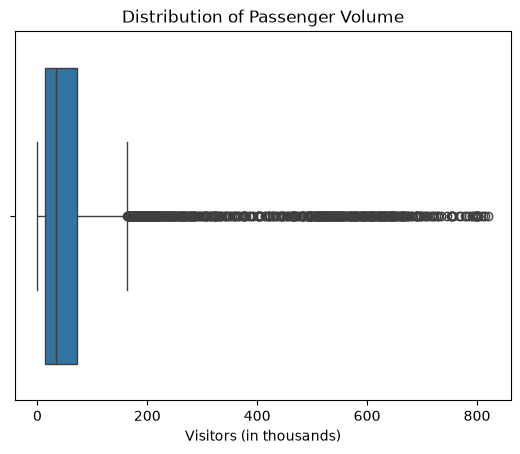

In [42]:
#Univariate 
sns.boxplot(x=df2['VALUE_in_thousands'])
plt.title('Distribution of Passenger Volume')
plt.xlabel('Visitors (in thousands)')
plt.show()

https://www.geeksforgeeks.org/data-visualization/what-is-univariate-bivariate-multivariate-analysis-in-data-visualisation/ tutorial how to use pie chart on EDA

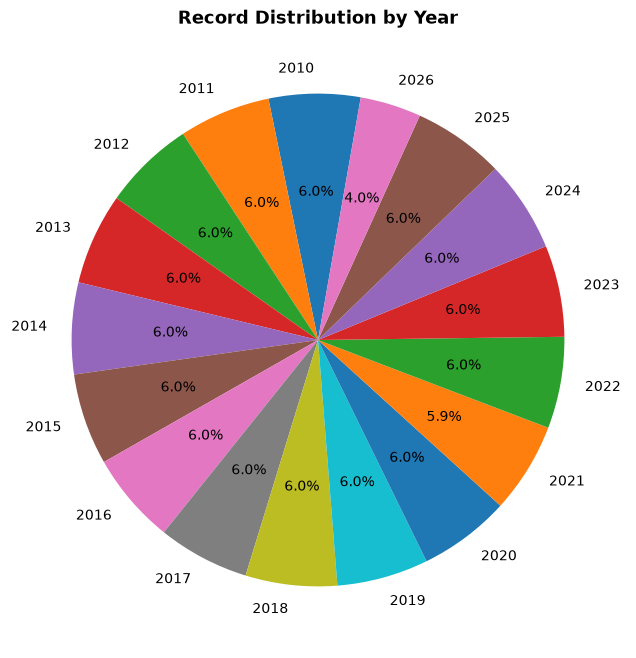

In [41]:
dfy = df2['Year'].value_counts().sort_index()
plt.figure(figsize=(8, 8))
plt.pie(dfy.values,labels=dfy.index,autopct='%1.1f%%',startangle=80)

plt.title('Record Distribution by Year', fontsize=13, fontweight='bold')
plt.show()

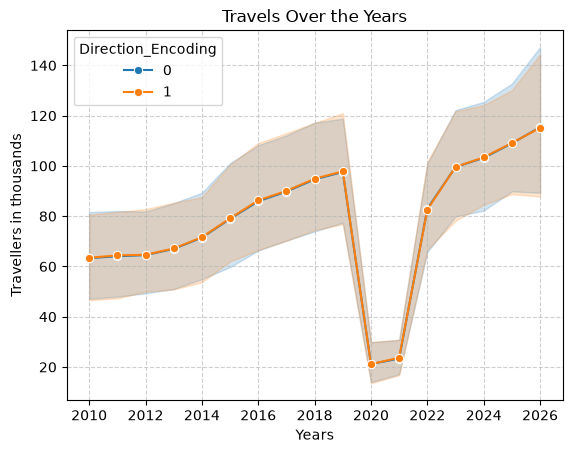

In [43]:
#Bivariate
sns.lineplot(
    data=df2,
    x="Year",
    y="VALUE_in_thousands",
    hue="Direction_Encoding",
    marker="o",
)
plt.title("Travels Over the Years")
plt.xlabel("Years")
plt.ylabel("Travellers in thousands")
plt.grid(True, linestyle="--", alpha=0.6)  
plt.show()

https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-groupby/ How to use groupby function.

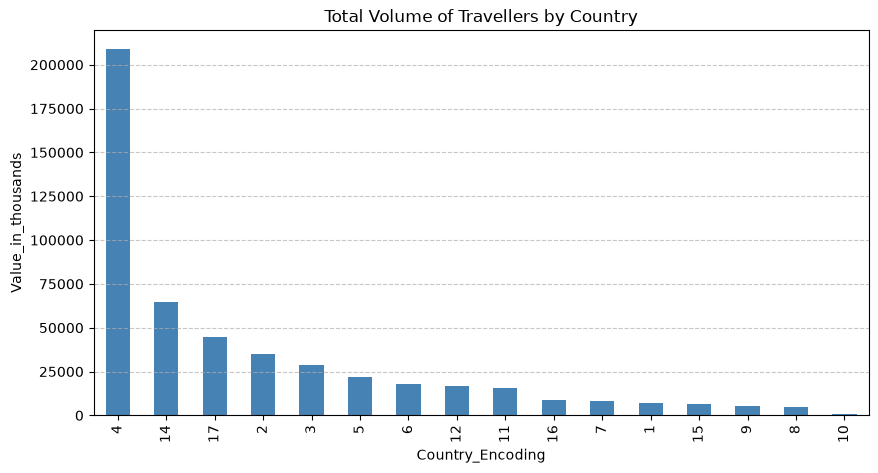

,Country,Country_Encoding
34,All countries,0
4,Belgium,1
10,France,2
6,Germany,3
0,Great Britain,4
12,Italy,5
14,Netherlands,6
32,Other Countries(42),7
24,Other Europe (34),8
28,Other Transatlantic Countries(1),9


In [46]:
#Bivariate
df2.groupby('Country_Encoding')['VALUE_in_thousands'].sum().sort_values(ascending=False).plot(kind='bar',figsize=(10, 5),color='steelblue')

plt.title('Total Volume of Travellers by Country')
plt.xlabel('Country_Encoding')
plt.ylabel('Value_in_thousands')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

df[['Country', 'Country_Encoding']].drop_duplicates().sort_values('Country_Encoding')

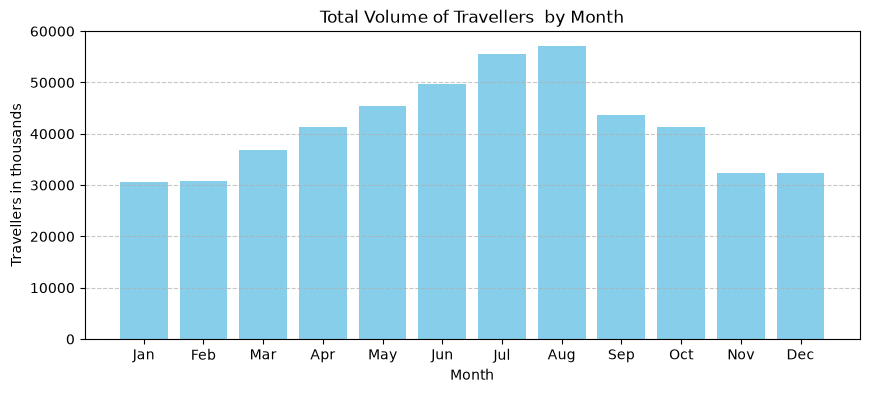

In [47]:
#Bivariate
df2_month = df2.groupby('Month_Encoding')['VALUE_in_thousands'].sum()
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(10, 4))
plt.bar(months, df2_month.values, color='skyblue')
plt.title('Total Volume of Travellers  by Month')
plt.xlabel('Month')
plt.ylabel('Travellers in thousands')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

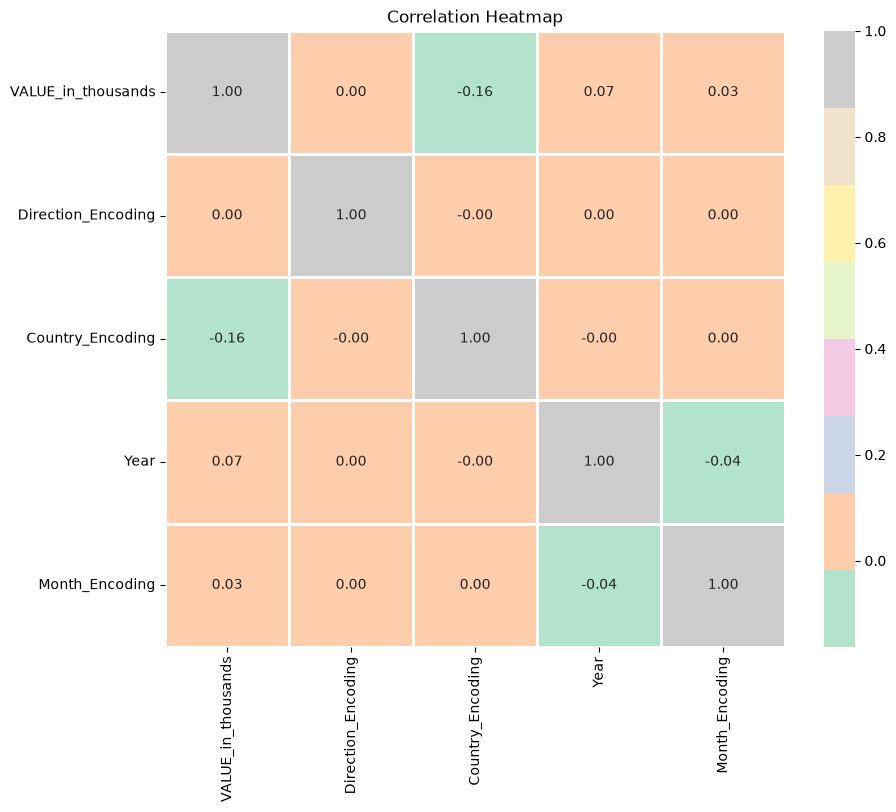

In [48]:
#Multivariate
plt.figure(figsize=(10, 8))
sns.heatmap(df2.corr(numeric_only=True),annot=True,fmt='.2f',cmap='Pastel2',linewidths=2)

plt.title('Correlation Heatmap')
plt.show()